# 01 - Clean and de-duplicate advertiser names

**Goal:** turn ~76k raw revenue rows from 6 different SSP exports into one clean table where each real advertiser appears once, so revenue per advertiser (and later, revenue share within a vertical) is correct.

**Why this comes before classification:** if "Tesco", "TESCO LIMITED" and `tesco_uk_q3` stay as three rows, we classify the same company three times and split its revenue across them. The "top advertiser share of category" metric would then be wrong.

**Input:** `data/raw/ssp_a.csv ... ssp_f.csv` (synthetic, generated by `src/generate_synthetic_data.py`)
**Output:** `data/processed/transactions_clean.csv` and `data/processed/advertisers.csv`, used by notebook 02.

**Steps:** 1) harmonize 6 schemas, 2) look at the mess, 3) rule-based cleaning, 4) fuzzy clustering, 5) measure how good it is, 6) check revenue concentration.

In [1]:
import subprocess, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src").exists():          # e.g. Google Colab: fetch the repo first
    subprocess.run(["git", "clone", "https://github.com/mayankg-data/advertiser-classification"], check=True)
    ROOT = ROOT / "advertiser-classification"
sys.path.insert(0, str(ROOT / "src"))

# Generate the synthetic data if it is not there yet (same seed -> same data for everyone)
if not (ROOT / "data" / "raw" / "ssp_a.csv").exists():
    subprocess.run([sys.executable, "src/generate_synthetic_data.py", "--n-tail", "2000", "--seed", "42"],
                   cwd=ROOT, check=True)

import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz import fuzz
from cleaning import load_and_harmonize, clean_name, match_key, cluster_keys

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 140)
RAW, OUT = ROOT / "data" / "raw", ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

## Step 1 - Harmonize the 6 SSP exports

Each SSP exports different column names, date formats and labels (`Mobile` / `smartphone` / `MOB`), and `ssp_b` reports revenue in **GBP** while the rest use USD. Before touching names I put everything on one schema:

`date, ssp, advertiser_raw, revenue_usd, device, position, geo`

**Design choices**
- Currency converted with a fixed GBP->USD rate (1.27) for simplicity. In production I would use the daily FX rate.
- Category labels mapped through one lookup per field. The loader asserts that nothing is left unmapped, so a new unseen label fails loudly instead of silently becoming NaN.

In [2]:
df = load_and_harmonize(RAW)
print(f"{len(df):,} rows | {df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d} | total revenue ${df.revenue_usd.sum():,.0f}")
print("nulls:", df.isna().sum().sum(), "| negative revenue rows:", (df.revenue_usd < 0).sum())
display(df.head())
display(df.groupby("ssp").agg(rows=("revenue_usd", "size"), revenue=("revenue_usd", "sum"),
                              raw_names=("advertiser_raw", "nunique")).round(0))

76,128 rows | 2024-01-01 to 2025-12-31 | total revenue $94,446,819
nulls: 0 | negative revenue rows: 0


,date,ssp,advertiser_raw,revenue_usd,device,position,geo
0,2024-02-21,ssp_a,PACIFIC MATCH CRICKET CLUB PTY LTD,71.98,desktop,atf,UK
1,2025-08-08,ssp_a,DISNEY+ INC,1528.98,mobile,atf,ROW
2,2024-11-28,ssp_a,IKEA LIMITED,8093.13,desktop,btf,US
3,2025-06-24,ssp_a,Costa Coffee,3821.91,mobile,atf,US
4,2024-05-30,ssp_a,Blue Stage Streaing,878.80,mobile,atf,US


,rows,revenue,raw_names
ssp,,,
ssp_a,12283,13126209.0,3551
ssp_b,12134,13464018.0,6304
ssp_c,12930,18344377.0,5047
ssp_d,12697,17759450.0,3431
ssp_e,13112,12460551.0,4924
ssp_f,12972,19292214.0,6489


## Step 2 - Look at the mess

Before writing cleaning rules, read the data. Here are random raw advertiser strings from each SSP.

In [3]:
sample = df.groupby("ssp").advertiser_raw.apply(lambda s: s.sample(5, random_state=1).tolist())
for ssp, names in sample.items():
    print(f"{ssp}: {names}")
print(f"\n{df.advertiser_raw.nunique():,} distinct raw name strings in the data")

ssp_a: ['Blue Rivet Auto Group', 'Care Health', 'RYANAIR PTY LTD', 'NOVA OPEN FOUNDATION LTD', 'Data Hosting 41']
ssp_b: ['PLAYBACK MEDIA 91 LIMITED', "KELLOGG'S INC", 'STERLING BANK 10 PLC', 'HARGREAVES LANSDOWN LIMITED', 'HSBC LIMITED']
ssp_c: ['uefa_2024', 'spice_brewery_us', 'wander_resorts_95_uk', 'deal_retail_2025', 'Fresh Snacks']
ssp_d: ['Island Airlines 56', 'premierleague.co.uk', 'Smoke Coffee Rosters', 'Brew Coffee Roasters 16', 'Tailor Apparel']
ssp_e: ['OPEN UNIVERSITY LIMITED', 'Havas | Data Broadband', 'Torque Auto Group 80', 'Publicis | Wander Hotels 36', 'Deal Mart']
ssp_f: ['Summit Harvest Beverages', 'Clearview Escape Crises', 'Gucci', 'crown_screen_productions_q2', 'river_island_au']

27,501 distinct raw name strings in the data


What I see: legal suffixes (`LTD`, `PLC`), agency prefixes (`Publicis | ...`), trailing IDs (`#48213`), campaign tags (`_q3`, `_uk`), domains (`tesco.co.uk`), and occasional typos. Each SSP has its own habits, which is why the same advertiser looks different across SSPs.

## Step 3 - Rule-based cleaning

Cheap, deterministic rules go first because they are explainable and fix the bulk of the problem:

1. strip agency prefix and trailing `#id`
2. turn domains back into names (`tesco.co.uk` -> `tesco`)
3. lowercase, drop apostrophes, turn other punctuation into spaces
4. peel trailing campaign tags and legal suffixes (`ltd`, `plc`, `q3`, `uk` ...)
5. build a **space-free match key**, so `nova apex motors` and `novaapexmotors` (from a domain) line up

In [4]:
df["clean"] = df.advertiser_raw.map(clean_name)
df["key"] = df.clean.map(match_key)

demo = ["GroupM | Tesco", "TESCO LTD", "tesco_uk_q3", "tesco.co.uk", "Tesco #48213",
        "Sainsbury's", "Mercedes-Benz", "mercedesbenz.com", "QANTAS PTY LTD"]
print(pd.DataFrame({"raw": demo, "clean": [clean_name(x) for x in demo]}).to_string(index=False))
print()
print(f"distinct raw names   : {df.advertiser_raw.nunique():>6,}")
print(f"after rule cleaning  : {df.clean.nunique():>6,}")
print(f"after match key      : {df.key.nunique():>6,}")

             raw         clean
  GroupM | Tesco         tesco
       TESCO LTD         tesco
     tesco_uk_q3         tesco
     tesco.co.uk         tesco
    Tesco #48213         tesco
     Sainsbury's    sainsburys
   Mercedes-Benz mercedes benz
mercedesbenz.com  mercedesbenz
  QANTAS PTY LTD        qantas

distinct raw names   : 27,501
after rule cleaning  :  6,579
after match key      :  5,508


Rules took us from ~27.5k strings to ~5.5k. What is left is mostly **typos** (`Tesc`, `Nke`) that no fixed rule can anticipate. That is where fuzzy matching comes in.

## Step 4 - Fuzzy clustering

Cluster the remaining keys with `rapidfuzz` (edit-distance similarity, 0-100).

**Design choices (each one fixes a specific failure I want to be able to explain):**
- **Process keys from highest revenue to lowest.** The cluster representative is then the most important variant, usually the correctly spelled one, and typos attach to it.
- **Digits must agree.** `island airlines 56` and `island airlines 57` are 95% similar as strings but are different advertisers.
- **Short keys (under 5 characters) match exactly only.** One typo on `ee` or `bt` looks identical to a different company.
- **Threshold = 90.** Chosen by looking at the error trade-off in Step 5.

In [5]:
THRESHOLD = 90
key_rev = df.groupby("key").revenue_usd.sum()
mapping = cluster_keys(key_rev, threshold=THRESHOLD)
df["cluster"] = df.key.map(mapping)
print(f"{df.key.nunique():,} keys -> {df.cluster.nunique():,} clusters (threshold {THRESHOLD})")

# Spot check 1: the biggest clusters and which variants landed in them
top = df.groupby("cluster").revenue_usd.sum().nlargest(5).index
for c in top:
    variants = df[df.cluster == c].advertiser_raw.value_counts().head(6).index.tolist()
    print(f"\n[{c}] e.g. {variants}")

5,508 keys -> 2,362 clusters (threshold 90)

[next] e.g. ['Next', 'next.com', 'next.co.uk', 'next_retarget', 'next.com.au', 'next.ie']

[dropbox] e.g. ['Dropbox', 'Havas | Dropbox', 'DROPBOX LIMITED', 'DROPBOX PLC', 'DROPBOX LTD', 'DROPBOX INC']

[ebay] e.g. ['eBay', 'EBAY LLC', 'ebay.com', 'EBAY INC', 'EBAY LTD', 'EBAY PTY LTD']

[itv] e.g. ['ITV', 'itv_display', 'itv_2025', 'itv_au', 'itv_prog', 'itv_q3']

[qantas] e.g. ['Qantas', 'qantas.com.au', 'Havas | Qantas', 'qantas.com', 'Dentsu | Qantas', 'qantas.co.uk']


In [6]:
# Spot check 2: the riskiest merges are the lowest-similarity ones. Read them by eye.
merged = pd.DataFrame({"key": list(mapping.keys()), "rep": list(mapping.values())})
merged = merged[merged.key != merged.rep]
merged["similarity"] = [fuzz.ratio(a, b) for a, b in zip(merged.key, merged.rep)]
print(f"{len(merged):,} keys were merged into another cluster. Lowest-similarity merges:")
merged.sort_values("similarity").head(10).reset_index(drop=True)

3,146 keys were merged into another cluster. Lowest-similarity merges:


,key,rep,similarity
0,spescavers,specsavers,90.0
1,warnrebros,warnerbros,90.0
2,vlokswagen,volkswagen,90.0
3,spicefodos,spicefoods,90.0
4,outletsohp,outletshop,90.0
5,meidhealth,medihealth,90.0
6,outlteshop,outletshop,90.0
7,volksawgen,volkswagen,90.0
8,lolydsbank,lloydsbank,90.0
9,sprnitfc32,sprintfc32,90.0


## Step 5 - How good is the de-duplication?

In a real project there is no answer key, so I would hand-check a sample of clusters and a sample of near-miss pairs. Here the data is synthetic, so I can compare against the true advertiser for every raw name and measure two kinds of error, both weighted by **revenue** (the business cares about dollars, not row counts):

- **Merge error** - revenue sitting in a cluster that belongs to a *different* advertiser than the cluster's majority. This corrupts the numbers: one advertiser's revenue is credited to another.
- **Split error** - revenue of an advertiser that is *not* in its largest cluster. This only fragments the tail, so the top advertiser's revenue is slightly understated.

(The ground-truth file is used for evaluation only. The pipeline above never reads it.)

In [7]:
truth = pd.read_csv(ROOT / "data" / "name_variants_truth.csv").drop_duplicates(["ssp", "advertiser_raw"])
ev = df.merge(truth, on=["ssp", "advertiser_raw"], how="left")
total = ev.revenue_usd.sum()

def errors(frame, col):
    g = frame.groupby([col, "canonical_advertiser"]).revenue_usd.sum().reset_index().sort_values("revenue_usd", ascending=False)
    merge_err = 1 - g.drop_duplicates(col).revenue_usd.sum() / total
    split_err = 1 - g.drop_duplicates("canonical_advertiser").revenue_usd.sum() / total
    return max(merge_err, 0), max(split_err, 0)

rows = [dict(method="rules only (no fuzzy)", clusters=ev.key.nunique(), **dict(zip(["merge_err_%", "split_err_%"], [100 * x for x in errors(ev, "key")])))]
for th in [80, 85, 88, 90, 92, 95]:
    m = cluster_keys(key_rev, threshold=th)
    ev["tmp"] = ev.key.map(m)
    rows.append(dict(method=f"fuzzy @ {th}", clusters=ev.tmp.nunique(),
                     **dict(zip(["merge_err_%", "split_err_%"], [100 * x for x in errors(ev, "tmp")]))))
sweep = pd.DataFrame(rows).round(2)
print(f"True number of advertisers: {ev.canonical_advertiser.nunique():,}")
sweep

True number of advertisers: 2,160


,method,clusters,merge_err_%,split_err_%
0,rules only (no fuzzy),5508,0.00,4.78
1,fuzzy @ 80,1734,2.46,0.26
2,fuzzy @ 85,2105,0.83,0.73
3,fuzzy @ 88,2304,0.19,1.40
4,fuzzy @ 90,2362,0.02,1.46
5,fuzzy @ 92,2627,0.00,2.11
6,fuzzy @ 95,3599,0.00,3.68


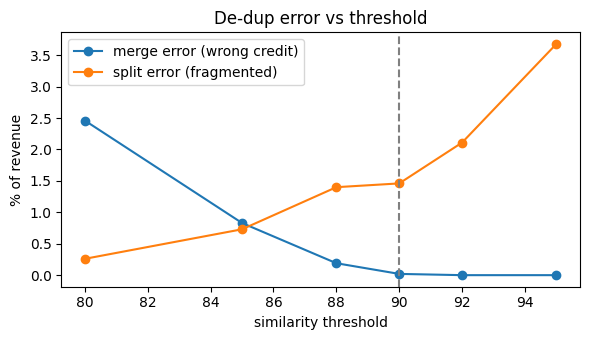

In [8]:
fz = sweep[sweep.method.str.startswith("fuzzy")].copy()
fz["th"] = fz.method.str.extract(r"(\d+)").astype(int)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(fz.th, fz["merge_err_%"], marker="o", label="merge error (wrong credit)")
ax.plot(fz.th, fz["split_err_%"], marker="o", label="split error (fragmented)")
ax.axvline(THRESHOLD, ls="--", c="grey")
ax.set_xlabel("similarity threshold"); ax.set_ylabel("% of revenue"); ax.legend(); ax.set_title("De-dup error vs threshold")
plt.tight_layout(); plt.show()

**Reading the table**
- Rules alone already give **zero merge error**, but leave ~5% of revenue fragmented across typo variants.
- A low threshold (80-85) fixes the splits but starts **merging different companies** (for example `Harvest Beverages` vs `Metro Harvest Beverages`, or `Vital Health` vs `Vitality Health`; at 85 there are about 290 such wrong merges).
- At **90**, merge error is about 0.02% and split error about 1.5%.

I choose 90 because the two errors are not equally bad. A wrong merge silently moves revenue between advertisers, so it can change a "top advertiser" ranking. A split only leaves a little revenue in small fragments. So I accept a bit more splitting to keep merges almost clean.

**What the remaining ~1.5% split is made of** (good to know for interviews): mostly adjacent-letter swaps such as `qanats` for Qantas or `drobpox` for Dropbox (a swap scores 83-87, just under 90), typo keys shorter than 5 characters that are only allowed exact matches (`aiva`, `mnzo`), and the ambiguous domain `booking.com`. A natural next improvement is an edit-distance rule that treats one transposition as a single edit.

## Step 6 - Build the clean advertiser table

For each cluster, the display name is the highest-revenue raw string that is already a plain brand name (so `eBay` stays `eBay`), falling back to a title-cased clean name. I also assign a stable `advertiser_id`.

In [9]:
# Display name: prefer a raw string that is already just the plain brand name (keeps "eBay", "H&M", "Disney+")
alnum = df.advertiser_raw.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
plain = df[(alnum == df.key) & (df.key == df.cluster)]
display_name = (plain.groupby(["cluster", "advertiser_raw"]).revenue_usd.sum().reset_index()
                     .sort_values("revenue_usd", ascending=False).drop_duplicates("cluster")
                     .set_index("cluster").advertiser_raw)
fallback = (df.groupby(["cluster", "clean"]).revenue_usd.sum().reset_index()
              .sort_values("revenue_usd", ascending=False).drop_duplicates("cluster")
              .set_index("cluster").clean.str.title())

adv = (df.groupby("cluster").agg(revenue_usd=("revenue_usd", "sum"),
                                 raw_variants=("advertiser_raw", "nunique"),
                                 ssps=("ssp", "nunique"))
         .sort_values("revenue_usd", ascending=False).reset_index())
adv["advertiser"] = adv.cluster.map(display_name).fillna(adv.cluster.map(fallback))
adv["advertiser_id"] = [f"A{i:05d}" for i in range(1, len(adv) + 1)]
adv["revenue_share"] = adv.revenue_usd / adv.revenue_usd.sum()
adv["cum_share"] = adv.revenue_share.cumsum()

df = df.merge(adv[["cluster", "advertiser_id", "advertiser"]], on="cluster")
df[["date", "ssp", "advertiser_id", "advertiser", "advertiser_raw", "revenue_usd", "device", "position", "geo"]] \
    .to_csv(OUT / "transactions_clean.csv", index=False)
adv[["advertiser_id", "advertiser", "revenue_usd", "revenue_share", "cum_share", "raw_variants", "ssps"]] \
    .to_csv(OUT / "advertisers.csv", index=False)

print(f"Saved {len(df):,} transactions and {len(adv):,} advertisers to {OUT}")
adv[["advertiser_id", "advertiser", "revenue_usd", "revenue_share", "raw_variants", "ssps"]].head(10).round(4)

Saved 76,128 transactions and 2,362 advertisers to /home/claude/advertiser-classification/data/processed


,advertiser_id,advertiser,revenue_usd,revenue_share,raw_variants,ssps
0,A00001,Next,3.571915e+06,0.0378,17,2
1,A00002,Dropbox,2.957566e+06,0.0313,24,3
2,A00003,eBay,2.056038e+06,0.0218,30,3
3,A00004,ITV,2.030083e+06,0.0215,17,2
4,A00005,Qantas,1.984083e+06,0.0210,25,3
5,A00006,Aviva,1.894676e+06,0.0201,17,2
6,A00007,Target,1.811786e+06,0.0192,46,4
7,A00008,Zara,1.577949e+06,0.0167,17,3
8,A00009,UEFA,1.529466e+06,0.0162,16,2
9,A00010,Nestle,1.336604e+06,0.0142,22,3


## Step 7 - Revenue concentration (why this shapes the next notebook)

top   47 advertisers ( 2.0% of advertisers) = 50% of revenue
top  166 advertisers ( 7.0% of advertisers) = 80% of revenue
top  405 advertisers (17.1% of advertisers) = 90% of revenue


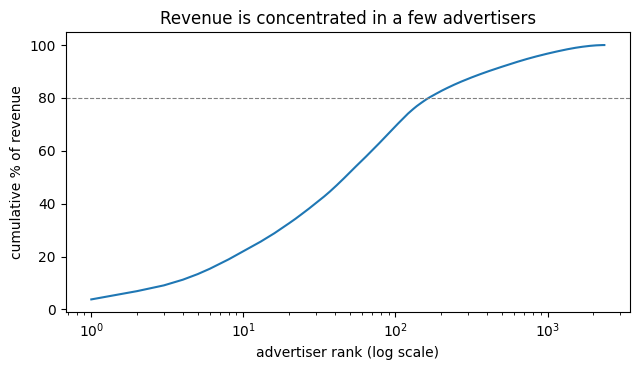

In [10]:
n = len(adv)
for p in [0.5, 0.8, 0.9]:
    k = int((adv.cum_share < p).sum()) + 1
    print(f"top {k:>4,} advertisers ({k / n:5.1%} of advertisers) = {p:.0%} of revenue")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(range(1, n + 1), adv.cum_share * 100)
ax.axhline(80, ls="--", c="grey", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel("advertiser rank (log scale)"); ax.set_ylabel("cumulative % of revenue")
ax.set_title("Revenue is concentrated in a few advertisers"); plt.tight_layout(); plt.show()

## Takeaways

- **Rules first, fuzzy second.** Rules are explainable and fix most of the mess; fuzzy matching only handles what rules cannot.
- **Evaluate by revenue and by error type.** Wrong merges and splits are not equally costly, and the threshold was chosen on that basis.
- **Revenue is heavily concentrated.** A few hundred advertisers carry most revenue, so in notebook 02 I label those carefully (LLM plus manual review) and use a cheaper model for the long tail.

**Limitations to mention honestly:** fixed FX rate; greedy clustering depends on processing order; short names cannot be fuzzy matched; domains with dots in the brand name are ambiguous; and on real data I would validate with a hand-checked sample rather than an answer key.

**Next:** `02_labeling` - label the top advertisers into the 10 verticals.